In [11]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
clean_data = pd.read_csv("ontario_school_boards_clean.csv")
print("Shape:", clean_data.shape)

Saving ontario_school_boards_clean.csv to ontario_school_boards_clean (2).csv
Shape: (79, 16)


In [33]:
analysis_data = clean_data.copy()
X = analysis_data[
    [
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ]
].copy()

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

if analysis_data["FiveYear_Graduation"].max() <= 1:
    provincial_benchmark = 0.895
else:
    provincial_benchmark = 89.5

analysis_data["Below_Benchmark"] = (
    analysis_data["FiveYear_Graduation"] < provincial_benchmark
).astype(int)

y = analysis_data["Below_Benchmark"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (79, 3)
y shape: (79,)

Target distribution:
Below_Benchmark
1    40
0    39
Name: count, dtype: int64


In [14]:
import pandas as pd
clean_data.columns = (
    clean_data.columns
    .str.replace("\xa0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Current columns:")
print(clean_data.columns.tolist())

Current columns:
['Board Number', 'Board_Name', 'Board_Language', 'Board Type', 'Region', 'City', 'Grade 10 OSSLT Results', 'Progress in Grade 10 OSSLT Results', 'Credit Accumulation by the end of Grade 10', 'Progress in Credit Accumulation by the end of Grade 10', 'Credit Accumulation by the end of Grade 11', 'Progress in Credit Accumulation by the end of Grade 11', 'Four Year Graduation Rate 2020-2021 Grade 9 Cohort', 'Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort', 'FiveYear_Graduation', 'Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort']


In [15]:
rename_map = {}

for col in clean_data.columns:

    name = col.lower()

    if "osslt" in name and "grade 10" in name:
        rename_map[col] = "Grade10_OSSLT"

    elif "credit" in name and "grade 10" in name:
        rename_map[col] = "Grade10_Credits"

    elif "credit" in name and "grade 11" in name:
        rename_map[col] = "Grade11_Credits"

    elif (
        "five year graduation" in name
        and "progress" not in name
    ):
        rename_map[col] = "FiveYear_Graduation"

clean_data = clean_data.rename(columns=rename_map)

print("\nRenamed columns:")
print(clean_data.columns.tolist())


Renamed columns:
['Board Number', 'Board_Name', 'Board_Language', 'Board Type', 'Region', 'City', 'Grade10_OSSLT', 'Grade10_OSSLT', 'Grade10_Credits', 'Grade10_Credits', 'Grade11_Credits', 'Grade11_Credits', 'Four Year Graduation Rate 2020-2021 Grade 9 Cohort', 'Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort', 'FiveYear_Graduation', 'Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort']


In [16]:
required_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]

for col in required_columns:
    print(col, ":", col in clean_data.columns)

Grade10_OSSLT : True
Grade10_Credits : True
Grade11_Credits : True
FiveYear_Graduation : True


In [17]:
print("Duplicate column names:")
print(clean_data.columns[clean_data.columns.duplicated()].tolist())

Duplicate column names:
['Grade10_OSSLT', 'Grade10_Credits', 'Grade11_Credits']


In [18]:
for col in [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]:
    print(col, "->", list(clean_data.columns).count(col))

Grade10_OSSLT -> 2
Grade10_Credits -> 2
Grade11_Credits -> 2
FiveYear_Graduation -> 1


In [19]:
clean_data = clean_data.loc[
    :, ~clean_data.columns.duplicated()
].copy()

In [20]:
for col in [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]:
    print(col, "->", list(clean_data.columns).count(col))

Grade10_OSSLT -> 1
Grade10_Credits -> 1
Grade11_Credits -> 1
FiveYear_Graduation -> 1


In [21]:
required_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]

for col in required_columns:

    clean_data[col] = (
        clean_data[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.replace("\xa0", "", regex=False)
        .str.strip()
    )

    clean_data[col] = pd.to_numeric(
        clean_data[col],
        errors="coerce"
    )

In [22]:
print(clean_data[required_columns].dtypes)

print("\nMissing values:")
print(clean_data[required_columns].isna().sum())

Grade10_OSSLT          float64
Grade10_Credits        float64
Grade11_Credits        float64
FiveYear_Graduation    float64
dtype: object

Missing values:
Grade10_OSSLT          7
Grade10_Credits        8
Grade11_Credits        8
FiveYear_Graduation    8
dtype: int64


In [23]:
X = clean_data[
    [
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ]
].copy()

if clean_data["FiveYear_Graduation"].max() <= 1:
    provincial_benchmark = 0.895
else:
    provincial_benchmark = 89.5

y = (
    clean_data["FiveYear_Graduation"]
    < provincial_benchmark
).astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (79, 3)
y shape: (79,)

Target distribution:
FiveYear_Graduation
1    40
0    39
Name: count, dtype: int64


In [24]:
required_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]

model_data = clean_data.dropna(
    subset=required_columns
).copy()

model_data = model_data.reset_index(drop=True)

print("Rows after removing incomplete records:", len(model_data))
print(model_data[required_columns].isna().sum())

Rows after removing incomplete records: 70
Grade10_OSSLT          0
Grade10_Credits        0
Grade11_Credits        0
FiveYear_Graduation    0
dtype: int64


In [40]:
X = model_data[
    [
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ]
].copy()

if model_data["FiveYear_Graduation"].max() <= 1:
    provincial_benchmark = 0.895
else:
    provincial_benchmark = 89.5

y = (
    model_data["FiveYear_Graduation"]
    < provincial_benchmark
).astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (70, 3)
y shape: (70,)

Target distribution:
FiveYear_Graduation
1    40
0    30
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import cross_validate
import pandas as pd

models = {
    "Majority Baseline": baseline,
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

timing_results = []

for name, model in models.items():
    result = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    timing_results.append({
        "Model": name,
        "Training Time (sec)": result["fit_time"].mean(),
        "Testing Time (sec)": result["score_time"].mean()
    })

timing_table = pd.DataFrame(timing_results)

timing_table.round(5)

,Model,Training Time (sec),Testing Time (sec)
0,Majority Baseline,0.00131,0.00136
1,Logistic Regression,0.00734,0.00346
2,Decision Tree,0.00339,0.00245


In [52]:
import pandas as pd
import numpy as np

from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score
from scipy.stats import wilcoxon

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "recall": "recall",
    "f1": "f1",
    "specificity": make_scorer(
        recall_score,
        pos_label=0
    )
}

log_results = cross_validate(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

tree_results = cross_validate(
    tree_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

fold_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],

    "Logistic Accuracy":
        log_results["test_accuracy"],

    "Tree Accuracy":
        tree_results["test_accuracy"],

    "Logistic Recall":
        log_results["test_recall"],

    "Tree Recall":
        tree_results["test_recall"],

    "Logistic F1":
        log_results["test_f1"],

    "Tree F1":
        tree_results["test_f1"],

    "Logistic Specificity":
        log_results["test_specificity"],

    "Tree Specificity":
        tree_results["test_specificity"]
})

fold_results.round(3)

,Fold,Logistic Accuracy,Tree Accuracy,Logistic Recall,Tree Recall,Logistic F1,Tree F1,Logistic Specificity,Tree Specificity
0,1,0.571,0.571,0.875,0.875,0.700,0.700,0.167,0.167
1,2,0.929,0.786,0.875,0.625,0.933,0.769,1.000,1.000
2,3,0.857,0.786,0.875,0.750,0.875,0.800,0.833,0.833
3,4,0.786,0.643,0.750,0.750,0.800,0.706,0.833,0.500
4,5,0.857,0.643,0.875,0.500,0.875,0.615,0.833,0.833


In [53]:
summary = fold_results.drop(
    columns="Fold"
).agg(["mean", "std"])

summary.round(3)

,Logistic Accuracy,Tree Accuracy,Logistic Recall,Tree Recall,Logistic F1,Tree F1,Logistic Specificity,Tree Specificity
mean,0.800,0.686,0.850,0.700,0.837,0.718,0.733,0.667
std,0.137,0.096,0.056,0.143,0.090,0.071,0.325,0.333


In [54]:
statistic, p_value = wilcoxon(
    fold_results["Logistic Recall"],
    fold_results["Tree Recall"],
    alternative="two-sided",
    zero_method="wilcox"
)

print("Wilcoxon statistic:", statistic)
print("p-value:", p_value)

Wilcoxon statistic: 0.0
p-value: 0.25


In [55]:
fold_results["Recall Difference"] = (
    fold_results["Logistic Recall"]
    - fold_results["Tree Recall"]
)

print(
    fold_results[
        ["Fold", "Logistic Recall",
         "Tree Recall", "Recall Difference"]
    ].round(3)
)

   Fold  Logistic Recall  Tree Recall  Recall Difference
0     1            0.875        0.875              0.000
1     2            0.875        0.625              0.250
2     3            0.875        0.750              0.125
3     4            0.750        0.750              0.000
4     5            0.875        0.500              0.375


In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logistic_model.fit(X, y)

coefficients = logistic_model.named_steps["logistic"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": [
        "Grade 10 OSSLT",
        "Grade 10 Credits",
        "Grade 11 Credits"
    ],
    "Coefficient": coefficients
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance["Odds Ratio"] = np.exp(
    feature_importance["Coefficient"]
)

feature_importance = feature_importance.sort_values(
    "Absolute Importance",
    ascending=False
)

print(feature_importance.round(3))

            Feature  Coefficient  Absolute Importance  Odds Ratio
2  Grade 11 Credits       -2.217                2.217       0.109
0    Grade 10 OSSLT       -0.557                0.557       0.573
1  Grade 10 Credits        0.369                0.369       1.447


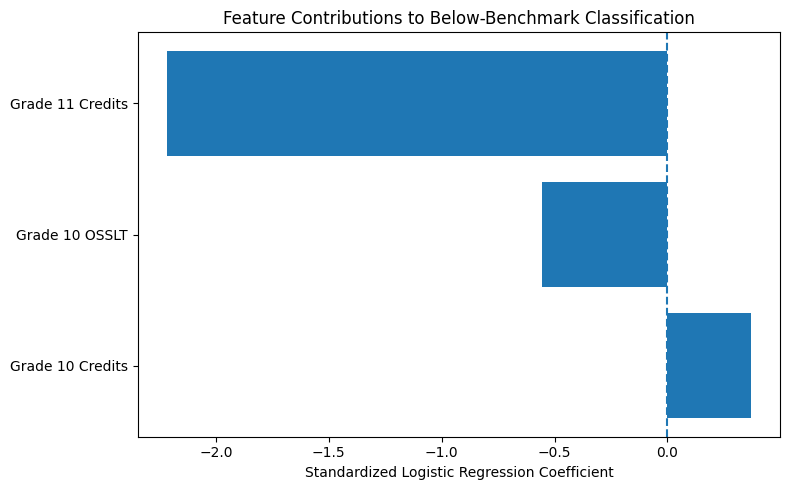

In [57]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Standardized Logistic Regression Coefficient")
plt.title("Feature Contributions to Below-Benchmark Classification")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    recall_score,
    precision_score,
    f1_score
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

baseline = DummyClassifier(
    strategy="most_frequent"
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)


repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)



scoring = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),

        "specificity": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    )
}

models = {
    "Majority Baseline": baseline,
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

all_results = []
summary_results = []

for model_name, model in models.items():

    result = cross_validate(
        model,
        X,
        y,
        cv=repeated_cv,
        scoring=scoring,
        return_train_score=False,
        error_score="raise"
    )


    for i in range(len(result["test_accuracy"])):

        all_results.append({
            "Model": model_name,
            "Run": i + 1,
            "Accuracy": result["test_accuracy"][i],
            "Precision": result["test_precision"][i],
            "Recall": result["test_recall"][i],
            "F1": result["test_f1"][i],
            "Specificity": result["test_specificity"][i],
            "Training Time": result["fit_time"][i],
            "Scoring Time": result["score_time"][i]
        })

        summary_results.append({
        "Model": model_name,

        "Accuracy Mean": result["test_accuracy"].mean(),
        "Accuracy SD": result["test_accuracy"].std(),

        "Precision Mean": result["test_precision"].mean(),
        "Precision SD": result["test_precision"].std(),

        "Recall Mean": result["test_recall"].mean(),
        "Recall SD": result["test_recall"].std(),

        "F1 Mean": result["test_f1"].mean(),
        "F1 SD": result["test_f1"].std(),

        "Specificity Mean": result["test_specificity"].mean(),
        "Specificity SD": result["test_specificity"].std(),

        "Training Time Mean": result["fit_time"].mean(),
        "Scoring Time Mean": result["score_time"].mean()
    })


all_results = pd.DataFrame(all_results)
comparison_table = pd.DataFrame(summary_results)

comparison_table.round(3)

,Model,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,Specificity Mean,Specificity SD,Training Time Mean,Scoring Time Mean
0,Majority Baseline,0.571,0.000,0.571,0.000,1.000,0.00,0.727,0.000,0.000,0.000,0.001,0.010
1,Majority Baseline,0.571,0.000,0.571,0.000,1.000,0.00,0.727,0.000,0.000,0.000,0.001,0.010
2,Majority Baseline,0.571,0.000,0.571,0.000,1.000,0.00,0.727,0.000,0.000,0.000,0.001,0.010
3,Majority Baseline,0.571,0.000,0.571,0.000,1.000,0.00,0.727,0.000,0.000,0.000,0.001,0.010
4,Majority Baseline,0.571,0.000,0.571,0.000,1.000,0.00,0.727,0.000,0.000,0.000,0.001,0.010
...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,Decision Tree,0.763,0.094,0.833,0.122,0.768,0.16,0.782,0.096,0.757,0.203,0.003,0.011
146,Decision Tree,0.763,0.094,0.833,0.122,0.768,0.16,0.782,0.096,0.757,0.203,0.003,0.011
147,Decision Tree,0.763,0.094,0.833,0.122,0.768,0.16,0.782,0.096,0.757,0.203,0.003,0.011
148,Decision Tree,0.763,0.094,0.833,0.122,0.768,0.16,0.782,0.096,0.757,0.203,0.003,0.011


In [46]:
stability_table = comparison_table[
    [
        "Model",
        "Accuracy Mean",
        "Accuracy SD",
        "Recall Mean",
        "Recall SD",
        "F1 Mean",
        "Specificity Mean"
    ]
]

stability_table.round(3)

,Model,Accuracy Mean,Accuracy SD,Recall Mean,Recall SD,F1 Mean,Specificity Mean
0,Majority Baseline,0.571,0.000,1.000,0.000,0.727,0.000
1,Logistic Regression,0.800,0.112,0.818,0.142,0.821,0.777
2,Decision Tree,0.763,0.094,0.768,0.160,0.782,0.757


In [47]:
efficiency_table = comparison_table[
    [
        "Model",
        "Training Time Mean",
        "Testing Time Mean"
    ]
].copy()

efficiency_table["Total Time Mean"] = (
    efficiency_table["Training Time Mean"]
    + efficiency_table["Testing Time Mean"]
)

efficiency_table.round(5)

,Model,Training Time Mean,Testing Time Mean,Total Time Mean
0,Majority Baseline,0.00146,0.01527,0.01673
1,Logistic Regression,0.01056,0.01878,0.02934
2,Decision Tree,0.00286,0.01145,0.01430


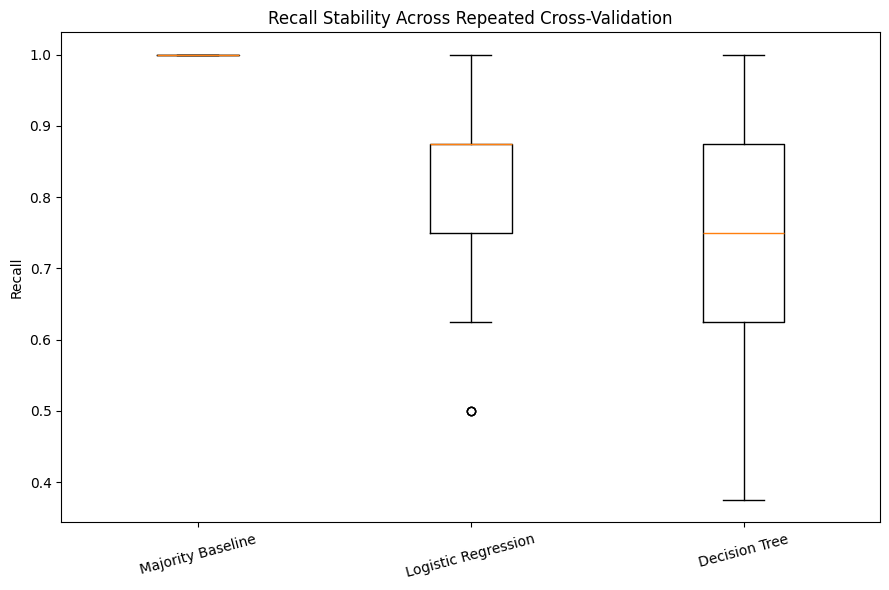

In [48]:
plt.figure(figsize=(9, 6))

data_to_plot = [
    all_results[
        all_results["Model"] == model
    ]["Recall"]
    for model in models.keys()
]

plt.boxplot(
    data_to_plot,
    tick_labels=list(models.keys())
)

plt.ylabel("Recall")
plt.title("Recall Stability Across Repeated Cross-Validation")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

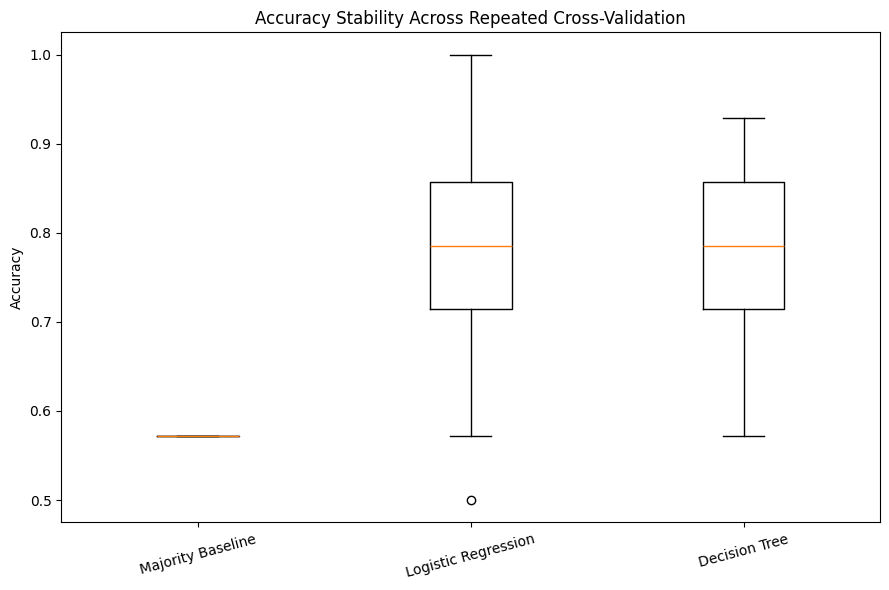

In [49]:
plt.figure(figsize=(9, 6))

data_to_plot = [
    all_results[
        all_results["Model"] == model
    ]["Accuracy"]
    for model in models.keys()
]

plt.boxplot(
    data_to_plot,
    tick_labels=list(models.keys())
)

plt.ylabel("Accuracy")
plt.title("Accuracy Stability Across Repeated Cross-Validation")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

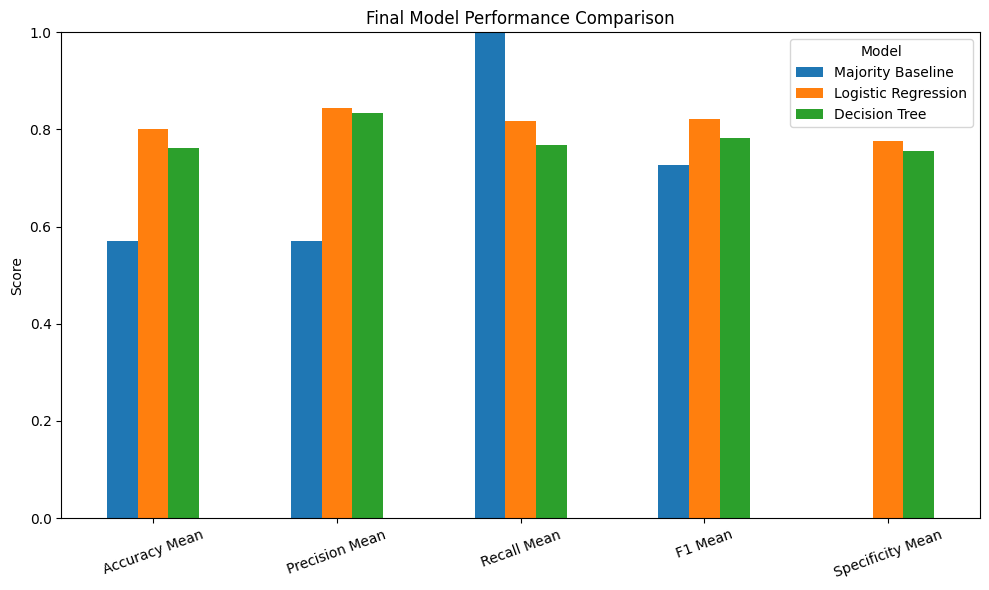

In [50]:
metrics = [
    "Accuracy Mean",
    "Precision Mean",
    "Recall Mean",
    "F1 Mean",
    "Specificity Mean"
]

plot_table = comparison_table.set_index("Model")[metrics].T

plot_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Final Model Performance Comparison")
plt.xticks(rotation=20)
plt.legend(title="Model")
plt.tight_layout()

plt.show()
